<!-- **Notes on Python virtual environment**

To activate the virtual environment, fix Windows bug then activate:
1. `Set-ExecutionPolicy Unrestricted -Scope Process`
2. `.venv\Scripts\activate` -->

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from algorithms import pgextra, nids, gf_pgextra
from sklearn.datasets import load_svmlight_file
import pickle

In [14]:
# Resolvent - soft thresholding operator
def soft_threshold(x, s):
    return np.sign(x) * np.clip(np.abs(x) - s, a_min=0, a_max=None) # Using numpy array operations

def JA(z, step, data):
    r"""
    Soft-thresholding operator: sgn(z[i])*max(abs(z[i])-\tau \lambda[i]), 0)
    """
    n = z.shape[0]
    JAz = np.zeros(z.shape)
    for ii in range(n):
        xi = z[ii,:-1].flatten()    # Extract variables xi, leave vi unchanged
        lambda_i = data['lambda'][ii]
        JAz[ii,:-1] = soft_threshold(xi, step*lambda_i)
    
    return JAz

def B(z, data):
    r"""
    Evaulate operator B(z) = [\grad_x fi(x, c); \grad_c fi(x,c)]
    """
    n = z.shape[0]
    mdims = data['m']
    Bz = np.zeros(z.shape)
    for ii in range(n):
        xi = z[ii, :-1].flatten()    # Extract variables xi
        bi = data['b'][ii]
        Abi = data['A'][ii]*bi # broadcast bi over columns of Ai
        
        pi = 1./(1+np.exp(-Abi@xi))
        Bz[ii,:-1] = (-1./mdims)*(Abi.T@(1-pi))
        Bz[ii,-1] = (-1./mdims)*np.dot(bi.flatten(),1-pi)
        
    return Bz

In [15]:
nagents = 20
dataset = 'colon'
subset = 200
# with open(r'C:\Users\TIMMSLF\OneDrive - The University of Melbourne\Documents\PhD\Code\Data_fast_pgextra\dict_of_log_instances_n20', 'rb') as f:
#     instance_dict = pickle.load(f)
# datadict = instance_dict[dataset] # Import dataset
# Amat = datadict['A']
# p, mdim = Amat[0].shape[1], datadict['m']

Xdata, ydata = load_svmlight_file(r'C:\Users\TIMMSLF\OneDrive - The University of Melbourne\Documents\PhD\Code\Data_fast_pgextra\\'+f'{dataset}')
Xdata, ydata = Xdata[:subset], ydata[:subset]   # Take subset of dataset
mdim = Xdata.shape[0]
d, p = Xdata.shape[0]//nagents, Xdata.shape[1]
Amat, bvec = {}, {}

for ii in range(nagents):
    if ii==nagents-1:
        Amat[ii] = Xdata[ii*d:].toarray()
        bvec[ii] = np.expand_dims(ydata[ii*d:], 1)
    else:
        Amat[ii] = Xdata[ii*d:(ii+1)*d].toarray()
        bvec[ii] = np.expand_dims(ydata[ii*d:(ii+1)*d], 1)
        
datadict = {'A': Amat, 'b': bvec, 'lambda': 0.015*np.ones(nagents), 'm': Xdata.shape[0]}

In [16]:
# Algorithm parameters
# Graph from PG-EXTRA
# edges = [(0,1),(0,3),(0,4),(0,6),
#          (1,6),
#          (2,6),(2,8),
#          (3,4),(3,6),(3,8),(3,9),
#          (4,5),
#          (5,8),(5,9),
#          (6,7),(6,8),
#          (7,9),
#          (8,9)]
G = nx.cycle_graph(nagents)

# Metropolis constant edge weight matrix
W = np.zeros((nagents, nagents))
for i,j in G.edges:
    W[i,j] = 1./(max(G.degree[i], G.degree[j])+1.) # w_ij = 1/(max{d_i, d_j}+\eps) for i,j\in Edges
    W[j, i] = W[i,j]
for i in range(nagents):
    W[i,i] = 1. - np.sum(W[i,:])    # w_ii = 1 - \sum_{j\in Edges} w_ij

# Algorithm step sizes and parameters
L = 0.25/mdim*np.max([  # Lipschitz constant L = max_i L_i
        np.linalg.svdvals(bvec[ii]*Amat[ii])[0]**2 + 2.*np.linalg.norm(np.sum(bvec[ii]**2*Amat[ii], axis=0)) + np.linalg.norm(bvec[ii])**2
    for ii in range(nagents)])
tau = 0.9 * (1 + np.min(np.linalg.eigvalsh(W))) / L  # tau <= (1-||K||^2)/L
thetainv = 2. - tau*L/(1 + np.min(np.linalg.eigvalsh(W)))   # 1/averaged constant of Condat-Vu operator
s = 0.9* thetainv # 0 < s < (4\beta_M-1)/(2\beta_M)
alpha = 5.
beta = 0.9/np.linalg.norm(tau*0.5*(np.eye(nagents)-W), ord=2)
maxit = 10000

def alpha_k(k):
    """Compute alpha(k) linearly increasing to 100*alpha0 at maxit/2 iterations
    :param a0: Initial alpha
    :param k: iteration number
    :param M: max iterations
    """
    if k<= (maxit//2):
        ak = alpha + 99*alpha*k/(maxit//2)
    else:
        ak = 100*alpha
    return ak

def sigma_k(k):
    return alpha_k(k)

In [17]:
x0 = np.zeros((nagents, p+1))   # p for weights and 1 for intercept/center

# Run PG-EXTRA, NIDS, and (normal) Fast PG-EXTRA
params = {'tau': tau, 'W': W, 'maxit': maxit}
zsol1, res_pg, rel_pg, con_pg = pgextra(x0, JA, B, params, data=datadict)
print()
params = {'tau': tau, 'beta': beta, 'W': W, 'maxit': maxit}
zsol2, res_nids, rel_nids, con_nids = nids(x0, JA, B, params, data=datadict)

# Initialise parameters & errors for Fast PG-EXTRA
etas = [0.1, 0.5, 0.8, 0.95, 1.0]
num_params = len(etas)

res_gfpg = np.zeros((num_params, maxit))
rel_gfpg = np.zeros((num_params, maxit))
con_gfpg = np.zeros((num_params, maxit))

# Run Generalised Fast PG-EXTRA for different etas and linear cooling alpha(k)
for ii in range(num_params):
    params = {'tau': tau,'s': s,'alpha': alpha_k,'sigma': sigma_k,'eta': etas[ii], 'W': W, 'maxit': maxit}
    print(f'\neta={etas[ii]:.2f}',end='\n')
    _, res_gfpg[ii,:], rel_gfpg[ii,:], con_gfpg[ii,:] = gf_pgextra(x0, JA, B, params, data=datadict)
print('')

# Run Generalised Fast PG-EXTRA with alpha(k)=500
params = {'tau': tau, 's': s, 'alpha': lambda k: 500., 'sigma': lambda k: 500., 'eta': 1.0, 'W': W, 'maxit': maxit}
_, res_gfpg500, rel_gfpg500, con_gfpg500 = gf_pgextra(x0, JA, B, params, data=datadict)


PG-EXTRA: iteration 10000 of 10000
NIDS: iteration 10000 of 10000
eta=0.10
Gen. Fast PG-EXTRA: iteration 10000 of 10000
eta=0.50
Gen. Fast PG-EXTRA: iteration 10000 of 10000
eta=0.80
Gen. Fast PG-EXTRA: iteration 10000 of 10000
eta=0.95
Gen. Fast PG-EXTRA: iteration 10000 of 10000
eta=1.00
Gen. Fast PG-EXTRA: iteration 10000 of 10000


In [20]:
print(f'desired nonzeros: 10% of {p}= {0.1*p}')
print(f'median # nonzeros: {np.mean([np.sum(np.abs(zsol2[ii])>1e-10) for ii in range(nagents)])}')

desired nonzeros: 10% of 2000= 200.0
median # nonzeros: 24.2


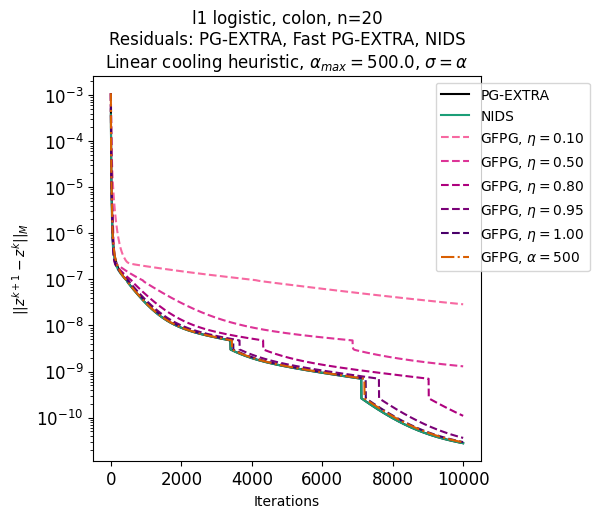

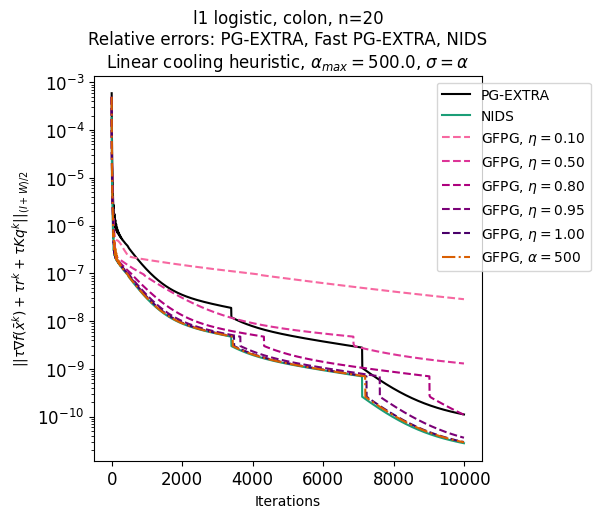

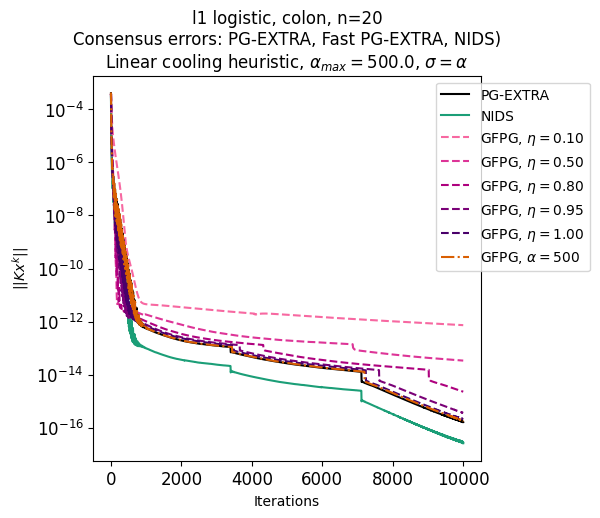

In [ ]:
colour = {'pg': 'k', 'nids': '#1b9e77', 'fpg': '#d95f02', '500': '#d95f02', 0: '#f768a1', 1: '#dd3497', 2: '#ae017e', 3: '#7a0177', 4: '#49006a'}

fig_res = plt.figure(figsize=(5, 5))
ax_res = fig_res.add_subplot(111)
scale_k = 1e-2
ax_res.semilogy(res_pg, color=colour['pg'], linestyle='-', label='PG-EXTRA')
ax_res.semilogy(res_nids, color=colour['nids'], linestyle='-', label='NIDS')
for ii in range(num_params):
    ax_res.semilogy(res_gfpg[ii], color=colour[ii], linestyle='--', label=r'GFPG, $\eta=$'+f'{etas[ii]:.2f}')
ax_res.semilogy(res_gfpg500, color=colour['500'], linestyle='-.', label=r'GFPG, $\alpha=500$')
ax_res.set_xlabel("Iterations")
ax_res.set_ylabel("$||z^{k+1}-z^k||_M$")
ax_res.set_title(f"l1 logistic, {dataset}, n={nagents}\nResiduals: PG-EXTRA, Fast PG-EXTRA, NIDS\nLinear cooling heuristic, "+r"$\alpha_{max}=$"+f"{100*alpha}, "+r"$\sigma=\alpha$")
ax_res.tick_params(axis='both', which='both', labelsize=12)
ax_res.legend(loc='upper right', bbox_to_anchor=(1.3, 1))
# ax_res.set_xlim([0, 100])

scale_k = 1e-5
fig_rel = plt.figure(figsize=(5, 5))
ax_rel = fig_rel.add_subplot(111)
ax_rel.semilogy(rel_pg, color=colour['pg'], linestyle='-', label='PG-EXTRA')
ax_rel.semilogy(rel_nids, color=colour['nids'], linestyle='-', label='NIDS')
for ii in range(num_params):
    ax_rel.semilogy(rel_gfpg[ii], color=colour[ii], linestyle='--', label=r'GFPG, $\eta=$'+f'{etas[ii]:.2f}')
ax_rel.semilogy(rel_gfpg500, color=colour['500'], linestyle='-.', label=r'GFPG, $\alpha=500$')
ax_rel.set_xlabel("Iterations")
ax_rel.set_ylabel(r"$||\tau \nabla f(\bar{x}^k)+\tau r^k+\tau Kq^k||_{(I+W)/2}$")
ax_rel.set_title(f"l1 logistic, {dataset}, n={nagents}\nRelative errors: PG-EXTRA, Fast PG-EXTRA, NIDS\nLinear cooling heuristic, "+r"$\alpha_{max}=$"+f"{100*alpha}, "+r"$\sigma=\alpha$")
ax_rel.tick_params(axis='both', which='both', labelsize=12)
ax_rel.legend(loc='upper right', bbox_to_anchor=(1.3, 1))
# ax_rel.set_xlim([0, 300])

fig_con = plt.figure(figsize=(5, 5))
ax_con = fig_con.add_subplot(111)
ax_con.semilogy(con_pg, color=colour['pg'], linestyle='-', label='PG-EXTRA')
ax_con.semilogy(con_nids, color=colour['nids'], linestyle='-', label='NIDS')
for ii in range(num_params):
    ax_con.semilogy(con_gfpg[ii], color=colour[ii], linestyle='--', label=r'GFPG, $\eta=$'+f'{etas[ii]:.2f}')
ax_con.semilogy(con_gfpg500, color=colour['500'], linestyle='-.', label=r'GFPG, $\alpha=500$')
ax_con.set_xlabel("Iterations")
ax_con.set_ylabel(r"$||Kx^k||$")
ax_con.set_title(f"l1 logistic, {dataset}, n={nagents}\nConsensus errors: PG-EXTRA, Fast PG-EXTRA, NIDS)\nLinear cooling heuristic, "+r"$\alpha_{max}=$"+f"{100*alpha}, "+r"$\sigma=\alpha$")
ax_con.tick_params(axis='both', which='both', labelsize=12)
ax_con.legend(loc='upper right', bbox_to_anchor=(1.3, 1))

filepath = r'C:\\Users\\TIMMSLF\\OneDrive - The University of Melbourne\\Documents\\PhD\\Code\\'
# fig_res.savefig(f'{filepath}\\Plots\\Fast_pgextra\\fast_pgextra_logistic_n20_res.pdf', bbox_inches='tight', pad_inches=0.2)
# fig_rel.savefig(f'{filepath}\\Plots\\Fast_pgextra\\fast_pgextra_logistic_n20_rel.pdf', bbox_inches='tight', pad_inches=0.2)
# fig_con.savefig(f'{filepath}\\Plots\\Fast_pgextra\\fast_pgextra_logistic_n20_con.pdf', bbox_inches='tight', pad_inches=0.2)